<a href="https://colab.research.google.com/github/Anshikakhandelwall/PhishingUrl-MLPBL/blob/main/phisihing_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The PhiUSIIL Phishing URL Dataset is a large collection of URLs used to detect phishing attempts.

Phishing URL - Websites Dataset (PhiUSIIL)

phishing is a common cybersecurity attack where attackers create fake URLs or websites to trick users into sharing sensitive information such as passwords, banking details, or login credentials.
The problem is that phishing URLs can sometimes look very similar to legitimate URLs, so simply looking at a URL isn't always enough to identify them.

Rows: 18445
Columns: 76

In [ ]:

# : IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

# Saving models
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

# PHASE 2: LOAD DATASET

df = pd.read_csv("/content/final_dataset.csv")

print("Dataset loaded successfully!")

print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Shape: (60662, 76)

First 5 rows:


,url,label,url_length,domain_length,hostname_length,path_length,first_dir_length,tld_length,tld_length_domain,url_depth,...,whois_success,domain_age_days,expiration_days,creation_year,domain_is_recent,domain_registered_before_2020,registrar_valid,name_servers_count,is_privacy_protected,whois_missing
0,http://%20%25**)(**@fbrasil.com/old/lqjj0ukuvg...,1,57,7,24,26,3,3,3,3,...,1.0,5484.0,359.0,2010.0,0.0,1.0,1.0,2.0,0.0,0.0
1,https://*f003.backblazeb2.com*/file/pesosi/hom...,1,52,4,22,22,4,0,0,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,http://0-docusign-secured-843439-1-srs09.repli...,1,52,6,44,1,0,3,3,0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,http://0-olx.1850943.xyz/,1,25,7,17,1,0,3,3,0,...,1.0,272.0,93.0,2025.0,1.0,0.0,1.0,2.0,0.0,0.0
4,http://0.0.0.0forum.cryptonight.net,1,35,11,28,0,0,3,3,0,...,1.0,475.0,254.0,2024.0,0.0,0.0,1.0,2.0,0.0,0.0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60662 entries, 0 to 60661
Data columns (total 76 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   url                            60662 non-null  object 
 1   label                          60662 non-null  int64  
 2   url_length                     60662 non-null  int64  
 3   domain_length                  60662 non-null  int64  
 4   hostname_length                60662 non-null  int64  
 5   path_length                    60662 non-null  int64  
 6   first_dir_length               60662 non-null  int64  
 7   tld_length                     60662 non-null  int64  
 8   tld_length_domain              60662 non-null  int64  
 9   url_depth                      60662 non-null  int64  
 10  query_length                   60662 non-null  int64  
 11  path_segments_count            60662 non-null  int64  
 12  num_digits              

In [ ]:

# BASIC DATASET UNDERSTANDING


print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns):
    print(i, col)

Number of rows: 60662
Number of columns: 76

Column names:
0 url
1 label
2 url_length
3 domain_length
4 hostname_length
5 path_length
6 first_dir_length
7 tld_length
8 tld_length_domain
9 url_depth
10 query_length
11 path_segments_count
12 num_digits
13 num_letters
14 num_special_chars
15 num_dots
16 num_hyphens
17 num_at
18 num_percent
19 num_equals
20 num_question
21 num_ampersand
22 num_hash
23 num_underscore
24 num_special
25 num_slash
26 num_params
27 entropy_url
28 entropy_hostname
29 entropy_domain
30 entropy_path
31 query_entropy
32 ratio_digits
33 ratio_letters
34 ratio_special_chars
35 uppercase_ratio
36 lowercase_ratio
37 is_ip_address
38 starts_with_ip
39 is_suspicious_tld
40 uses_https
41 has_www
42 unusual_double_slash
43 multiple_http
44 contains_port_number
45 path_has_encoded_chars
46 query_has_base64
47 contains_login
48 contains_secure
49 contains_verify
50 contains_account
51 contains_update
52 contains_bank
53 contains_cloud
54 contains_brand
55 query_key_count
56 

In [ ]:
# Target variable
target = "label"

print("Target variable:", target)

print("\nTarget distribution:")
print(df[target].value_counts())

print("\nTarget percentage:")
print(df[target].value_counts(normalize=True) * 100)

Target variable: label

Target distribution:
label
1    36265
0    24397
Name: count, dtype: int64

Target percentage:
label
1    59.782071
0    40.217929
Name: proportion, dtype: float64


In [ ]:

#  DATA CLEANING


print("Missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate URLs:")
print(df["url"].duplicated().sum())

Missing values:
18

Duplicate rows:
0

Duplicate URLs:
0


In [ ]:
print("Number of rows before dropping NaNs:", df.shape[0])

df.dropna(inplace=True)

print("Number of rows after dropping NaNs:", df.shape[0])
print("Missing values after dropping NaNs:", df.isnull().sum().sum())

Number of rows before dropping NaNs: 60662
Number of rows after dropping NaNs: 60661
Missing values after dropping NaNs: 0


In [ ]:
print(df.dtypes.value_counts())

int64      45
float64    30
object      1
Name: count, dtype: int64


**Exploratory Data Analysis**

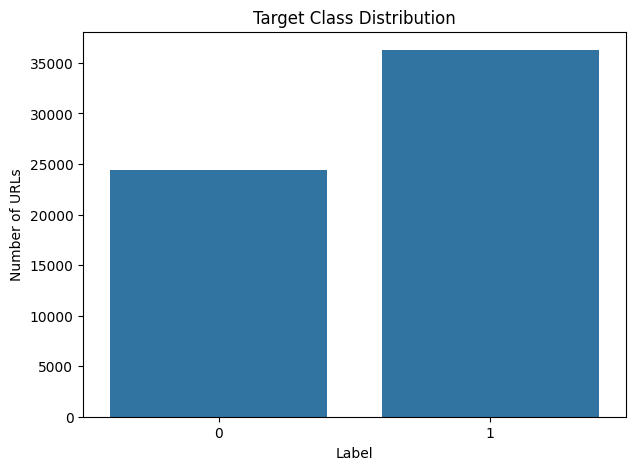

In [ ]:

# TARGET DISTRIBUTION


plt.figure(figsize=(7, 5))

sns.countplot(x=df[target])

plt.title("Target Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of URLs")

plt.show()

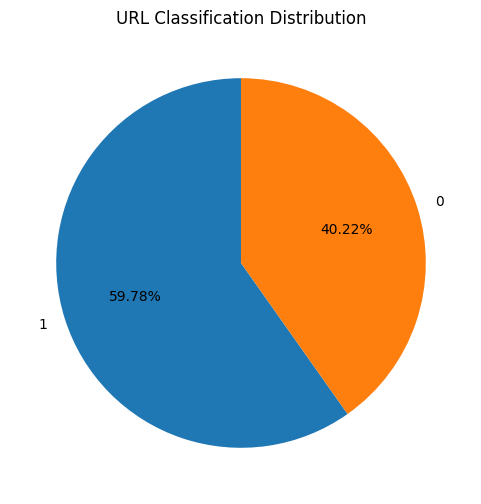

In [ ]:
plt.figure(figsize=(6, 6))

df[target].value_counts().plot(
    kind="pie",
    autopct="%1.2f%%",
    startangle=90
)

plt.title("URL Classification Distribution")
plt.ylabel("")

plt.show()

**Separate Features and Target**

In [ ]:
# FEATURE / TARGET SEPARATION


X = df.drop(columns=["url", "label"])
y = df["label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (60661, 74)
Target shape: (60661,)

Features:
['url_length', 'domain_length', 'hostname_length', 'path_length', 'first_dir_length', 'tld_length', 'tld_length_domain', 'url_depth', 'query_length', 'path_segments_count', 'num_digits', 'num_letters', 'num_special_chars', 'num_dots', 'num_hyphens', 'num_at', 'num_percent', 'num_equals', 'num_question', 'num_ampersand', 'num_hash', 'num_underscore', 'num_special', 'num_slash', 'num_params', 'entropy_url', 'entropy_hostname', 'entropy_domain', 'entropy_path', 'query_entropy', 'ratio_digits', 'ratio_letters', 'ratio_special_chars', 'uppercase_ratio', 'lowercase_ratio', 'is_ip_address', 'starts_with_ip', 'is_suspicious_tld', 'uses_https', 'has_www', 'unusual_double_slash', 'multiple_http', 'contains_port_number', 'path_has_encoded_chars', 'query_has_base64', 'contains_login', 'contains_secure', 'contains_verify', 'contains_account', 'contains_update', 'contains_bank', 'contains_cloud', 'contains_brand', 'query_key_count', 'query

Train/Test Split

We will use:

80% → training
20% → testing

stratify=y keeps the class distribution approximately the same.

In [ ]:

# TRAIN TEST SPLIT


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

Training data: (48528, 74)
Testing data: (12133, 74)

Training class distribution:
label
1    0.59784
0    0.40216
Name: proportion, dtype: float64

Testing class distribution:
label
1    0.597791
0    0.402209
Name: proportion, dtype: float64


Feature Scaling

Scaling is particularly useful for:

Logistic Regression
KNN

Tree-based models generally don't require scaling.

We'll create a pipeline so scaling is performed correctly without leaking test information into training.

In [ ]:

# PHASE 8: FEATURE SCALING


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")

Scaling completed!


In [ ]:

#  LOGISTIC REGRESSION


logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained!")

Logistic Regression trained!


In [ ]:

# PHASE 9.2: DECISION TREE


dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=20
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree trained!")

Decision Tree trained!


Random Forest

Random Forest is especially suitable for your dataset because you have many engineered numerical/binary URL features.

In [ ]:
# ============================================
# PHASE 10: RANDOM FOREST
# ============================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=25,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest trained!")

Random Forest trained!


**Evaluate All Models**

In [ ]:

# PHASE 13: MODEL EVALUATION FUNCTION


def evaluate_model(model_name, y_true, y_pred, y_prob):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_lr,
        y_prob_lr
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt,
        y_prob_dt
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf,
        y_prob_rf
    )
)



results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.981950,0.992026,0.977664,0.984793,0.998394
1,Decision Tree,0.973131,0.984202,0.970633,0.977371,0.969217
0,Logistic Regression,0.958460,0.970576,0.959603,0.965058,0.992162


**VISUALISE MODEL COMPARISON**

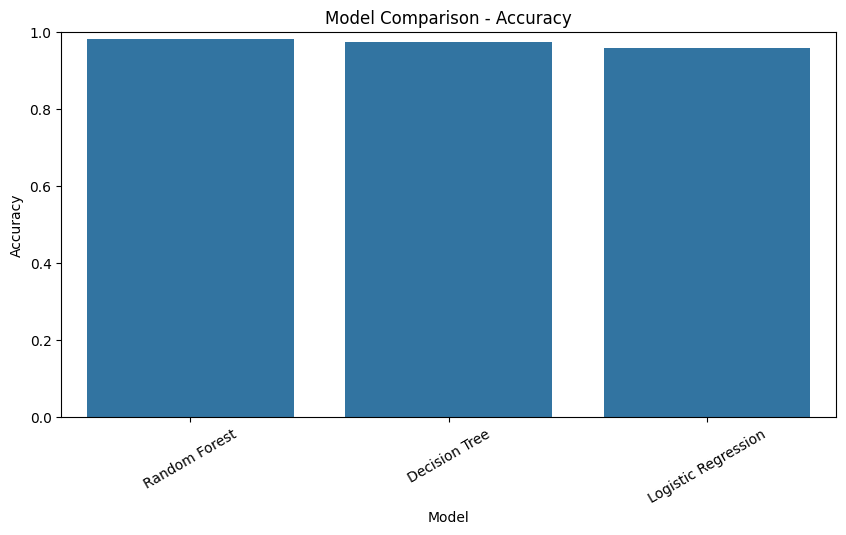

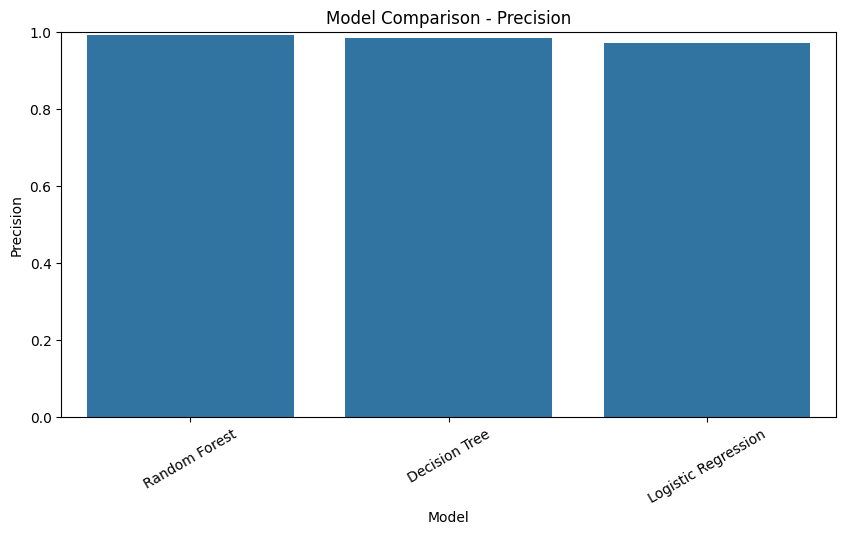

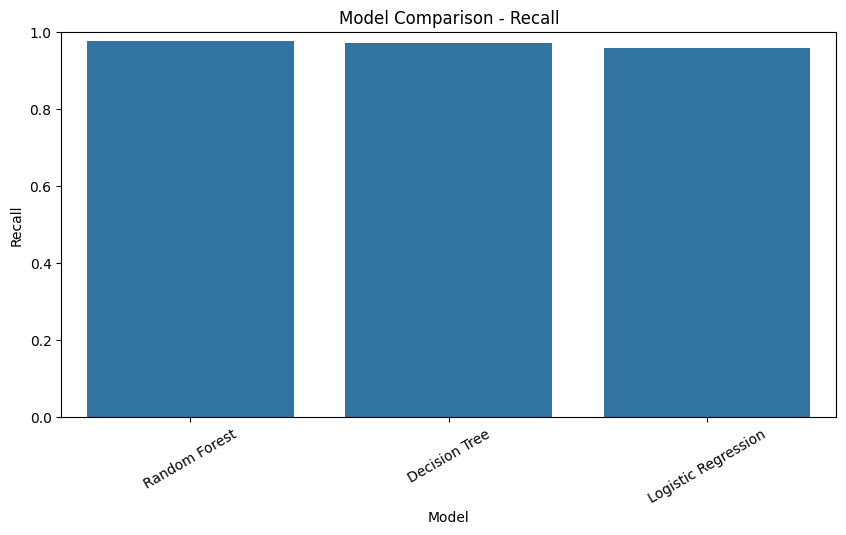

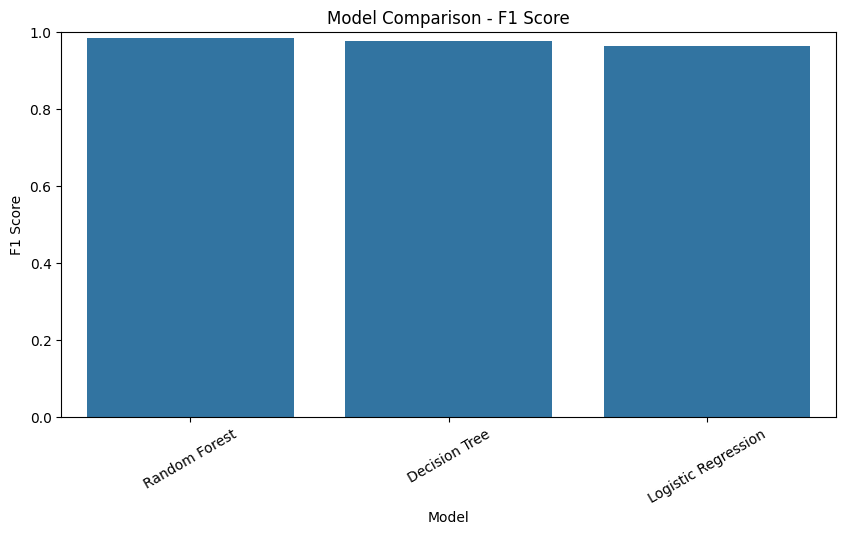

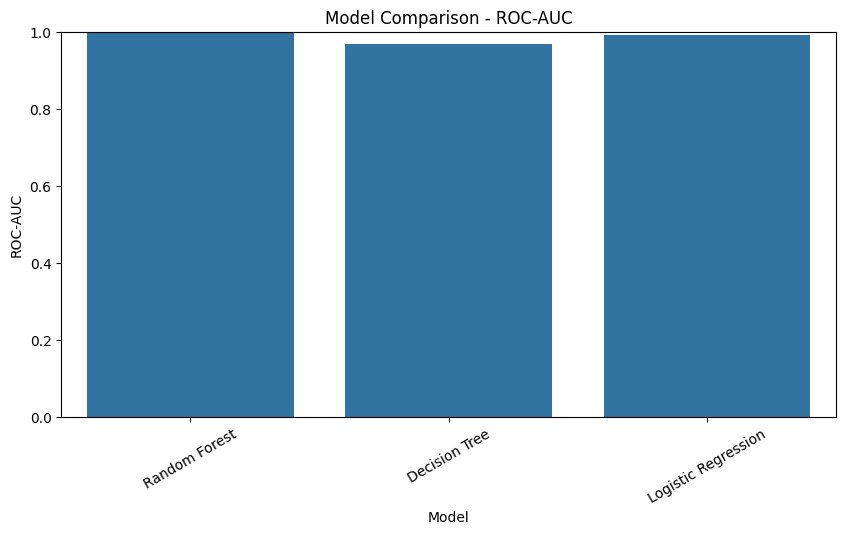

In [ ]:

#  MODEL COMPARISON


metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=30)
    plt.ylim(0, 1)

    plt.show()

**Confusion Matrix for Best Model**

In [ ]:

# PHASE 15: FIND BEST MODEL


best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [ ]:
model_predictions = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Decision Tree": (y_pred_dt, y_prob_dt),
    "Random Forest": (y_pred_rf, y_prob_rf),

}

best_predictions, best_probabilities = model_predictions[best_model_name]

**CONFUSION MATRIX**

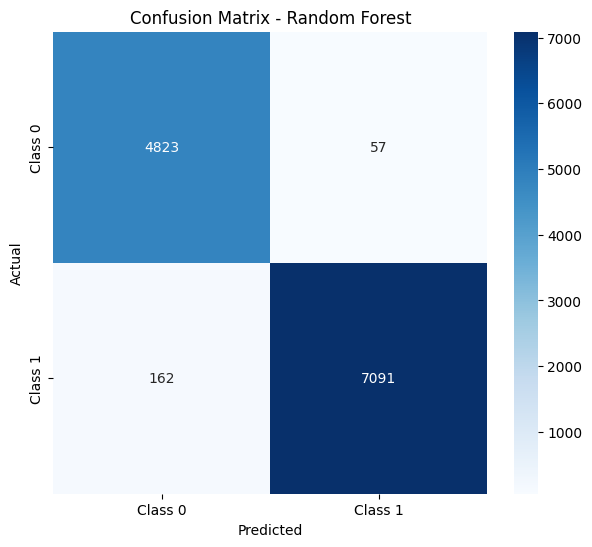

In [ ]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

**Classification Report**

In [ ]:
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Class 0", "Class 1"]
    )
)

              precision    recall  f1-score   support

     Class 0       0.97      0.99      0.98      4880
     Class 1       0.99      0.98      0.98      7253

    accuracy                           0.98     12133
   macro avg       0.98      0.98      0.98     12133
weighted avg       0.98      0.98      0.98     12133



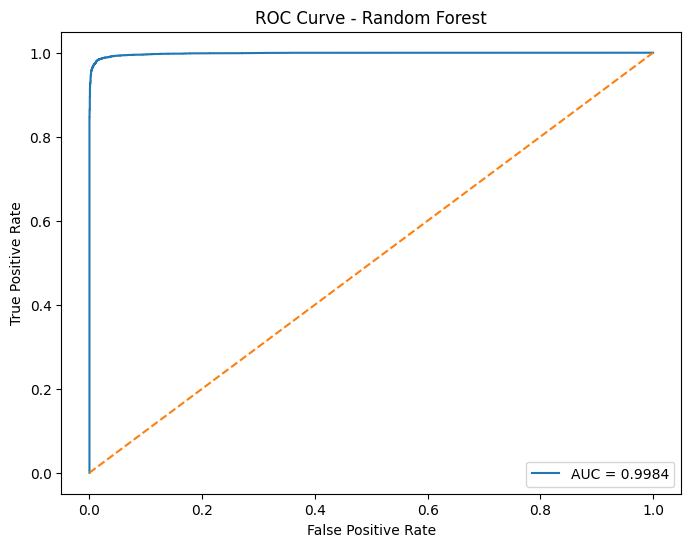

In [ ]:

# ROC CURVE


fpr, tpr, thresholds = roc_curve(
    y_test,
    best_probabilities
)

auc_score = roc_auc_score(
    y_test,
    best_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc_score:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(f"ROC Curve - {best_model_name}")

plt.legend()

plt.show()

Feature Importance

This is particularly important for your project because you can explain which URL characteristics influence malicious/benign classification.

For tree-based models:

In [ ]:

# PHASE 18: FEATURE IMPORTANCE


if hasattr(rf_model, "feature_importances_"):

    feature_importance = pd.DataFrame({
        "Feature": X.columns,
        "Importance": rf_model.feature_importances_
    })

    feature_importance = feature_importance.sort_values(
        by="Importance",
        ascending=False
    )

    display(feature_importance.head(20))

,Feature,Importance
57,has_mx_record,0.103225
2,hostname_length,0.061208
28,entropy_path,0.056402
39,has_www,0.055917
59,has_ns_record,0.053452
60,ttl_value,0.050264
26,entropy_hostname,0.048946
56,dns_resolves,0.048609
65,domain_age_days,0.033498
3,path_length,0.032952


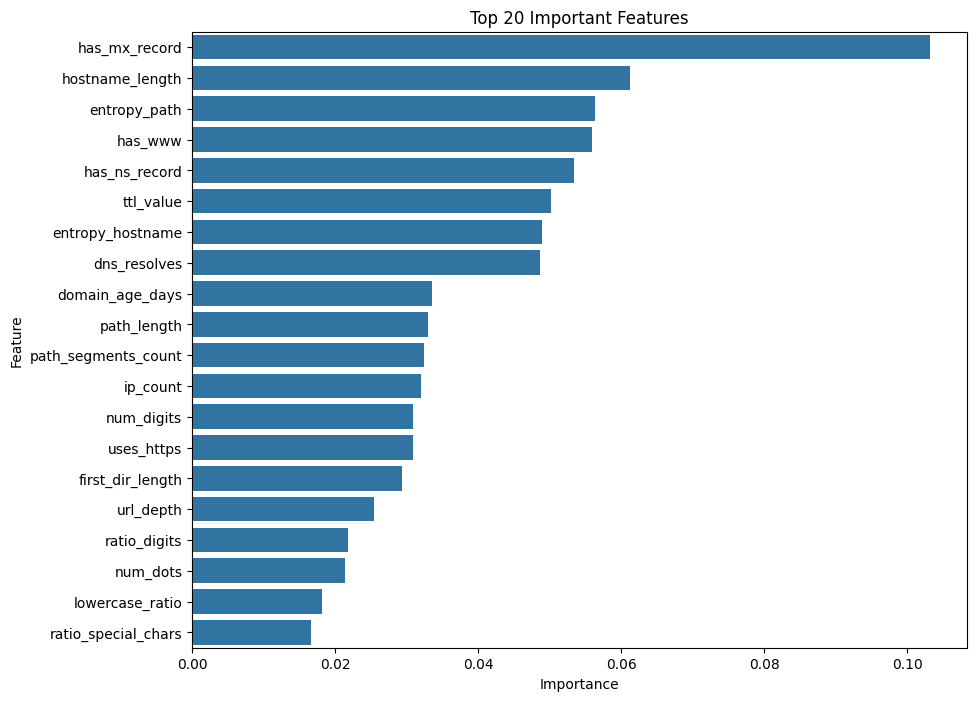

In [ ]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Important Features")

plt.show()

In [ ]:

#  SAVE MODELS


models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,

}

In [ ]:
best_model = models[best_model_name]

joblib.dump(
    best_model,
    "best_url_classifier.pkl"
)

joblib.dump(
    X.columns.tolist(),
    "feature_columns.pkl"
)

print("Best model saved successfully!")
print("Model:", best_model_name)

Best model saved successfully!
Model: Random Forest


In [ ]:
joblib.dump(
    scaler,
    "feature_scaler.pkl"
)

print("Scaler saved!")

Scaler saved!


In [ ]:

#  LOAD SAVED MODEL


loaded_model = joblib.load(
    "best_url_classifier.pkl"
)

feature_columns = joblib.load(
    "feature_columns.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
unseen_data = X_test.iloc[[0]].copy()

In [ ]:

# UNSEEN DATA PREDICTION


unseen_sample = X_test.iloc[[0]].copy()

prediction = loaded_model.predict(
    unseen_sample
)

probability = loaded_model.predict_proba(
    unseen_sample
)

print("Predicted class:", prediction[0])
print("Probability:", probability[0])

Predicted class: 0
Probability: [0.89336965 0.10663035]


In [ ]:
if prediction[0] == 1:
    print("Prediction: MALICIOUS / SUSPICIOUS URL")
else:
    print("Prediction: LEGITIMATE URL")

Prediction: LEGITIMATE URL


In [ ]:

# PREDICTION FUNCTION


def predict_url_features(input_data):

    loaded_model = joblib.load(
        "best_url_classifier.pkl"
    )

    feature_columns = joblib.load(
        "feature_columns.pkl"
    )

    # Ensure same feature order
    input_data = input_data[feature_columns]

    prediction = loaded_model.predict(input_data)[0]

    probability = loaded_model.predict_proba(
        input_data
    )[0]

    return prediction, probability

In [ ]:
prediction, probability = predict_url_features(
    unseen_sample
)

print("Prediction:", prediction)
print("Class 0 probability:", probability[0])
print("Class 1 probability:", probability[1])

Prediction: 0
Class 0 probability: 0.8933696492125559
Class 1 probability: 0.10663035078744412


To predict on new, raw URLs, we need to first extract the same 74 features that the model was trained on. This involves a custom function that parses the URL and computes each characteristic.

**Note on Network-Based Features**: Some features (`dns_resolves`, `has_mx_record`, `whois_success`, `domain_age_days`, `ttl_value`, `ip_count`, `cname_count`, `resolves_to_private_ip`, `creation_year`, `domain_is_recent`, `domain_registered_before_2020`, `registrar_valid`, `name_servers_count`, `is_privacy_protected`, `whois_missing`) require external network requests (DNS lookups, WHOIS queries). For a quick demonstration and to avoid external dependencies and potential delays, these features will be initialized to a default value (e.g., 0 or -1). To fully implement them, you would need libraries like `socket`, `dns.resolver` (for `dnspython`), and `python-whois` or similar, and handle network timeouts/errors.

Let's start by importing necessary libraries for URL parsing and feature extraction.

In [ ]:
!pip install tldextract

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [tldextract]


In [ ]:
import urllib.parse
import tldextract
import re
import math
import ipaddress
import pandas as pd # Added pandas import here
import numpy as np # Added numpy import here as it's used in calculate_entropy and query_value_length_avg
import joblib # Added joblib import here

# Helper function for entropy calculation (re-using from potential original feature engineering)
def calculate_entropy(text):
    if not text: return 0
    freq = pd.Series(list(text)).value_counts(normalize=True)
    entropy = - (freq * np.log2(freq)).sum()
    return entropy

def extract_features_from_url(url):
    features = {}
    parsed_url = urllib.parse.urlparse(url)
    extracted_tld = tldextract.extract(url)

    # 1. URL Length Features
    features['url_length'] = len(url)
    features['domain_length'] = len(extracted_tld.domain + '.' + extracted_tld.suffix) if extracted_tld.domain and extracted_tld.suffix else 0
    features['hostname_length'] = len(parsed_url.hostname) if parsed_url.hostname else 0
    features['path_length'] = len(parsed_url.path)
    features['first_dir_length'] = len(parsed_url.path.split('/')[1]) if parsed_url.path and len(parsed_url.path.split('/')) > 1 else 0
    features['tld_length'] = len(extracted_tld.suffix) if extracted_tld.suffix else 0
    features['tld_length_domain'] = len(extracted_tld.suffix) if extracted_tld.suffix else 0 # Assuming same as tld_length if only one TLD concept

    # 2. URL Structure Features
    features['url_depth'] = parsed_url.path.count('/')
    features['query_length'] = len(parsed_url.query)
    features['path_segments_count'] = len([segment for segment in parsed_url.path.split('/') if segment])

    # 3. Character Counts
    features['num_digits'] = sum(c.isdigit() for c in url)
    features['num_letters'] = sum(c.isalpha() for c in url)
    features['num_special_chars'] = len(re.findall(r'[^a-zA-Z0-9]', url))
    features['num_dots'] = url.count('.')
    features['num_hyphens'] = url.count('-')
    features['num_at'] = url.count('@')
    features['num_percent'] = url.count('%')
    features['num_equals'] = url.count('=')
    features['num_question'] = url.count('?')
    features['num_ampersand'] = url.count('&')
    features['num_hash'] = url.count('#')
    features['num_underscore'] = url.count('_')
    features['num_special'] = features['num_at'] + features['num_percent'] + features['num_equals'] + features['num_question'] + features['num_ampersand'] + features['num_hash'] + features['num_underscore']
    features['num_slash'] = url.count('/')
    features['num_params'] = len(urllib.parse.parse_qs(parsed_url.query)) # Number of unique parameters

    # 4. Entropy Features
    features['entropy_url'] = calculate_entropy(url)
    features['entropy_hostname'] = calculate_entropy(parsed_url.hostname) if parsed_url.hostname else 0
    features['entropy_domain'] = calculate_entropy(extracted_tld.domain) if extracted_tld.domain else 0
    features['entropy_path'] = calculate_entropy(parsed_url.path) if parsed_url.path else 0
    features['query_entropy'] = calculate_entropy(parsed_url.query) if parsed_url.query else 0

    # 5. Ratio Features
    features['ratio_digits'] = features['num_digits'] / features['url_length'] if features['url_length'] > 0 else 0
    features['ratio_letters'] = features['num_letters'] / features['url_length'] if features['url_length'] > 0 else 0
    features['ratio_special_chars'] = features['num_special_chars'] / features['url_length'] if features['url_length'] > 0 else 0
    features['uppercase_ratio'] = sum(1 for c in url if c.isupper()) / features['url_length'] if features['url_length'] > 0 else 0
    features['lowercase_ratio'] = sum(1 for c in url if c.islower()) / features['url_length'] if features['url_length'] > 0 else 0

    # 6. Boolean Flags
    features['is_ip_address'] = 1 if re.match(r'^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}$', parsed_url.hostname) else 0
    features['starts_with_ip'] = 1 if features['is_ip_address'] else 0 # Assuming starts_with_ip is related to is_ip_address
    features['is_suspicious_tld'] = 1 if extracted_tld.suffix in ['zip', 'ru', 'cn', 'tk'] else 0 # Example suspicious TLDs
    features['uses_https'] = 1 if parsed_url.scheme == 'https' else 0
    features['has_www'] = 1 if parsed_url.hostname and parsed_url.hostname.startswith('www.') else 0
    features['unusual_double_slash'] = 1 if '//' in parsed_url.path else 0 # Check for double slashes in path, common in phishing
    features['multiple_http'] = 1 if url.count('http') > 1 else 0
    features['contains_port_number'] = 1 if parsed_url.port else 0
    features['path_has_encoded_chars'] = 1 if '%' in parsed_url.path else 0
    features['query_has_base64'] = 1 if re.search(r'[A-Za-z0-9+/=]{20,}', parsed_url.query) else 0 # Simple check for long base64-like strings

    # Keywords in URL
    features['contains_login'] = 1 if 'login' in url.lower() else 0
    features['contains_secure'] = 1 if 'secure' in url.lower() else 0
    features['contains_verify'] = 1 if 'verify' in url.lower() else 0
    features['contains_account'] = 1 if 'account' in url.lower() else 0
    features['contains_update'] = 1 if 'update' in url.lower() else 0
    features['contains_bank'] = 1 if 'bank' in url.lower() else 0
    features['contains_cloud'] = 1 if 'cloud' in url.lower() else 0
    features['contains_brand'] = 1 if any(brand in url.lower() for brand in ['paypal', 'ebay', 'amazon', 'google', 'apple']) else 0 # Example brands

    # Query Parameter Features
    query_params = urllib.parse.parse_qs(parsed_url.query)
    features['query_key_count'] = len(query_params)
    features['query_value_length_avg'] = np.mean([len(v[0]) for v in query_params.values()]) if query_params else 0

    # Network/DNS/WHOIS Features (PLACEHOLDERS for now)
    # These would require actual network calls and potentially external libraries (e.g., `socket`, `dnspython`, `python-whois`)
    features['success'] = 0 # Placeholder
    features['dns_resolves'] = 0 # Placeholder
    features['has_mx_record'] = 0 # Placeholder
    features['has_txt_record'] = 0 # Placeholder
    features['has_ns_record'] = 0 # Placeholder
    features['ttl_value'] = -1 # Placeholder, actual TTL in seconds
    features['ip_count'] = 0 # Placeholder
    features['cname_count'] = 0 # Placeholder
    features['resolves_to_private_ip'] = 0 # Placeholder
    features['whois_success'] = 0 # Placeholder
    features['domain_age_days'] = -1 # Placeholder, calculate from creation_date
    features['expiration_days'] = -1 # Placeholder, calculate from expiration_date
    features['creation_year'] = -1 # Placeholder
    features['domain_is_recent'] = 0 # Placeholder (e.g., < 30 days old)
    features['domain_registered_before_2020'] = 0 # Placeholder
    features['registrar_valid'] = 0 # Placeholder
    features['name_servers_count'] = 0 # Placeholder
    features['is_privacy_protected'] = 0 # Placeholder
    features['whois_missing'] = 0 # Placeholder

    # Ensure the order of features matches the trained model's expected order
    # Load feature_columns to ensure correct order
    loaded_feature_columns = joblib.load('feature_columns.pkl')
    extracted_df = pd.DataFrame([features])[loaded_feature_columns]

    return extracted_df

Now, let's create a wrapper function `predict_raw_url` that takes a raw URL string, extracts its features using the function we just defined, scales the numerical features, and then makes a prediction using the loaded best model.

In [ ]:
def predict_raw_url(raw_url):
    # 1. Extract features from the raw URL
    features_df = extract_features_from_url(raw_url)

    # 2. Load the scaler (if applicable for the best model)
    # Assuming the best model (Random Forest) was trained on unscaled data based on your notebook
    # However, Logistic Regression used scaled data. For a robust prediction function, we should check
    # if the best model requires scaling.
    # For simplicity, if best_model_name is 'Logistic Regression', we'd load and apply scaler.
    # Given 'Random Forest' is best, we'll proceed without scaling for now, but keep this in mind for other models.

    # You can add logic here: if loaded_model requires scaling, then load and apply the scaler.
    # For Random Forest, scaling is not typically required.

    # If you were using Logistic Regression as the best model, you'd do something like:
    # if loaded_model.__class__.__name__ == 'LogisticRegression':
    #     loaded_scaler = joblib.load('feature_scaler.pkl')
    #     features_scaled = loaded_scaler.transform(features_df)
    # else:
    #     features_scaled = features_df # No scaling needed
    # For this notebook's best model (Random Forest), no scaling is applied before prediction.

    # 3. Make prediction
    prediction = loaded_model.predict(features_df)[0]
    probability = loaded_model.predict_proba(features_df)[0]

    return prediction, probability


print("Raw URL prediction function defined!")

Raw URL prediction function defined!


Let's test our new `predict_raw_url` function with some example URLs.

In [ ]:
# Example 1: A legitimate URL
legit_url = "https://www.google.com/search?q=python+programming"
prediction_legit, prob_legit = predict_raw_url(legit_url)

print(f"Raw URL: {legit_url}")
print(f"Predicted class: {prediction_legit} ({'MALICIOUS' if prediction_legit == 1 else 'LEGITIMATE'})")
print(f"Probability (Class 0 - LEGITIMATE): {prob_legit[0]:.4f}")
print(f"Probability (Class 1 - MALICIOUS): {prob_legit[1]:.4f}")
print("\n" + "-"*50 + "\n")

# Example 2: A simulated phishing URL
# This URL is crafted to trigger some of the string-based features often found in phishing
phishing_url = "http://paypallogin.verification.com-security.xyz/update/account/billing?id=123456789"
prediction_phish, prob_phish = predict_raw_url(phishing_url)

print(f"Raw URL: {phishing_url}")
print(f"Predicted class: {prediction_phish} ({'MALICIOUS' if prediction_phish == 1 else 'LEGITIMATE'})")
print(f"Probability (Class 0 - LEGITIMATE): {prob_phish[0]:.4f}")
print(f"Probability (Class 1 - MALICIOUS): {prob_phish[1]:.4f}")
print("\n" + "-"*50 + "\n")

# Example 3: Another legitimate URL
another_legit_url = "https://colab.research.google.com/notebooks/intro.ipynb"
prediction_another_legit, prob_another_legit = predict_raw_url(another_legit_url)

print(f"Raw URL: {another_legit_url}")
print(f"Predicted class: {prediction_another_legit} ({'MALICIOUS' if prediction_another_legit == 1 else 'LEGITIMATE'})")
print(f"Probability (Class 0 - LEGITIMATE): {prob_another_legit[0]:.4f}")
print(f"Probability (Class 1 - MALICIOUS): {prob_another_legit[1]:.4f}")

Raw URL: https://www.google.com/search?q=python+programming
Predicted class: 1 (MALICIOUS)
Probability (Class 0 - LEGITIMATE): 0.0988
Probability (Class 1 - MALICIOUS): 0.9012

--------------------------------------------------

Raw URL: http://paypallogin.verification.com-security.xyz/update/account/billing?id=123456789
Predicted class: 1 (MALICIOUS)
Probability (Class 0 - LEGITIMATE): 0.0000
Probability (Class 1 - MALICIOUS): 1.0000

--------------------------------------------------

Raw URL: https://colab.research.google.com/notebooks/intro.ipynb
Predicted class: 1 (MALICIOUS)
Probability (Class 0 - LEGITIMATE): 0.0083
Probability (Class 1 - MALICIOUS): 0.9917


### Debugging: Features for `https://www.google.com`

Let's extract and display the features for the URL `https://www.google.com` to understand why it might be misclassified.

In [ ]:
legit_url = "https://www.google.com"
extracted_google_features = extract_features_from_url(legit_url)
print(f"Features for: {legit_url}")
display(extracted_google_features)


Features for: https://www.google.com


,url_length,domain_length,hostname_length,path_length,first_dir_length,tld_length,tld_length_domain,url_depth,query_length,path_segments_count,...,whois_success,domain_age_days,expiration_days,creation_year,domain_is_recent,domain_registered_before_2020,registrar_valid,name_servers_count,is_privacy_protected,whois_missing
0,22,10,14,0,0,3,3,0,0,0,...,0,-1,-1,-1,0,0,0,0,0,0


In [ ]:
display(extracted_google_features[['uses_https', 'has_www', 'contains_brand']])

,uses_https,has_www,contains_brand
0,1,1,1


### Explaining Predictions with SHAP and LIME

To understand why the model classifies a specific URL as legitimate or malicious, we will use two popular Explainable AI (XAI) libraries:
1. **SHAP (SHapley Additive exPlanations)**: Provides game-theory-based explanations of the contribution of each feature to the prediction.
2. **LIME (Local Interpretable Model-agnostic Explanations)**: Explains the decision locally by fitting a simple interpretable model around the prediction point.

In [ ]:
!pip install shap lime

In [ ]:
import shap
from lime import lime_tabular

# Initialize SHAP explainer
# Since we are using a tree-based model (Random Forest), we can use TreeExplainer
shap_explainer = shap.TreeExplainer(loaded_model)

# Initialize LIME explainer on the training dataset
lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=feature_columns,
    class_names=['LEGITIMATE', 'MALICIOUS'],
    mode='classification'
)

print("SHAP and LIME explainers initialized successfully!")

Let's create an explanation wrapper function that takes a raw URL, extracts its features, and produces both SHAP and LIME visualization plots.

In [ ]:
def explain_url_prediction(raw_url):
    # 1. Extract features
    features_df = extract_features_from_url(raw_url)

    # 2. Get predictions
    pred = loaded_model.predict(features_df)[0]
    prob = loaded_model.predict_proba(features_df)[0]

    print(f"URL: {raw_url}")
    print(f"Prediction: {'MALICIOUS' if pred == 1 else 'LEGITIMATE'} (Probability: {prob[pred]:.4f})")
    print("\n" + "="*60 + "\n")

    # 3. LIME Explanation
    print("--- LIME Explanation (Local Features) ---")
    lime_exp = lime_explainer.explain_instance(
        data_row=features_df.iloc[0],
        predict_fn=loaded_model.predict_proba,
        num_features=10
    )
    lime_exp.show_in_notebook(show_table=True, show_all=False)

    # 4. SHAP Explanation
    print("\n--- SHAP Explanation (Waterfall Force Plot) ---")
    shap_values = shap_explainer(features_df)
    # We plot the force plot or waterfall plot for Class 1 (Malicious contribution)
    shap.plots.force(
        shap_explainer.expected_value[1],
        shap_values.values[0][:, 1],
        features_df.iloc[0],
        matplotlib=True
    )

Let's test this explainer on our example phishing URL to understand its classification.

URL: http://paypallogin.verification.com-security.xyz/update/account/billing?id=123456789
Prediction: MALICIOUS (Probability: 1.0000)


--- LIME Explanation (Local Features) ---



--- SHAP Explanation (Waterfall Force Plot) ---


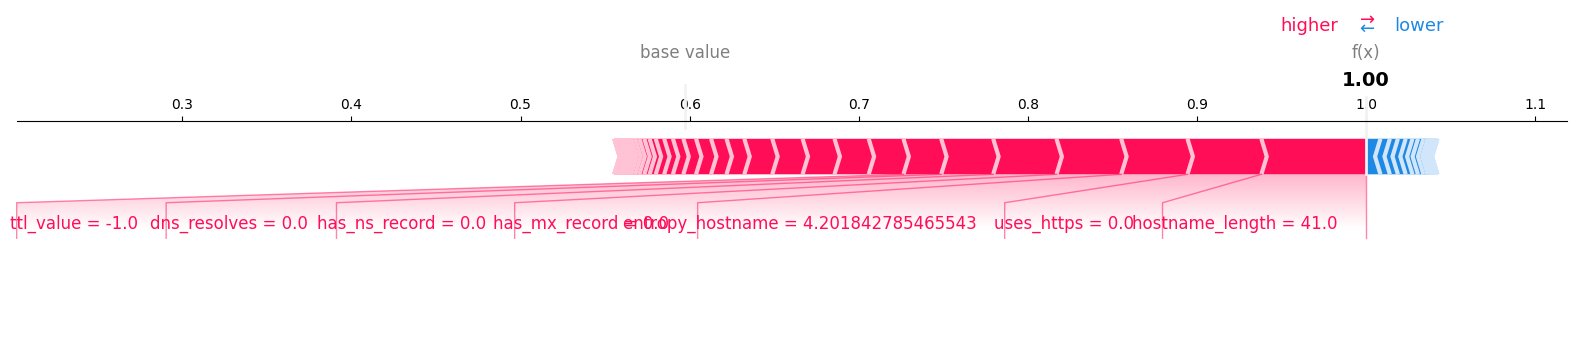

In [ ]:
explain_url_prediction("http://paypallogin.verification.com-security.xyz/update/account/billing?id=123456789")

### Translating the Technical Explanations into Simple English

To make our model's predictions accessible to anyone without a data science background, we will write a function that translates the URL characteristics into plain, simple English findings.

In [ ]:
def explain_url_in_simple_english(raw_url):
    # 1. Extract features
    features_df = extract_features_from_url(raw_url)

    # 2. Get predictions
    pred = loaded_model.predict(features_df)[0]
    prob = loaded_model.predict_proba(features_df)[0]

    print(f"🔍 ANALYZING URL: {raw_url}\n")

    # Summary
    if pred == 1:
        print(f"🚨 ALERT: This website link is highly suspicious and likely a PHISHING attempt! (Confidence: {prob[1]*100:.1f}%)")
    else:
        print(f"✅ SAFE: This website link looks LEGITIMATE and safe to visit. (Confidence: {prob[0]*100:.1f}%)")

    print("\n--- WHY DID THE COMPUTER THINK THIS? (Simple Breakdown) ---")

    # Analyze key indicators
    reasons = []

    # Secure connection check
    if features_df['uses_https'].iloc[0] == 0:
        reasons.append("⚠️ No Secure Connection: The website does not use 'https://' encryption, meaning any information you type can be stolen easily.")

    # Keyword warnings
    keywords_found = []
    for word in ['login', 'secure', 'verify', 'account', 'update', 'bank']:
        if features_df[f'contains_{word}'].iloc[0] == 1:
            keywords_found.append(f"'{word}'")
    if keywords_found:
        reasons.append(f"⚠️ Trapping Keywords: The link contains sensitive words like {', '.join(keywords_found)} which fake pages often use to trick you into entering details.")

    # Brand name tricks
    if features_df['contains_brand'].iloc[0] == 1:
         reasons.append("⚠️ Brand Name Mentioned: The link uses a major brand name (like PayPal, Google, or Amazon) in a weird place, which is a common trick to look real.")

    # Domain structure complexity
    if features_df['url_length'].iloc[0] > 70:
        reasons.append(f"⚠️ Very Long Link: The link is {features_df['url_length'].iloc[0]} characters long. Real websites usually have short, clear links.")

    # Numbers & Special Characters
    if features_df['ratio_digits'].iloc[0] > 0.15:
        reasons.append("⚠️ Random Numbers: The link is cluttered with a high amount of numbers, which is typical for automatically generated spam links.")

    if features_df['num_dots'].iloc[0] >= 3:
        reasons.append(f"⚠️ Too Many Dots: There are {features_df['num_dots'].iloc[0]} dots in the domain name. It might be pretending to be a subdomain of a real company.")

    # If it's safe and none of the bad indicators were triggered
    if not reasons:
        if pred == 0:
            reasons.append("✨ Clean Structure: The link has a normal length, uses secure encryption ('https'), has no strange numbers, and avoids deceptive trap words.")
        else:
            reasons.append("⚠️ Suspicious Structural Signature: The overall pattern and length of letters in the link match patterns commonly used by online scammers.")

    for reason in reasons:
        print(reason)

Let's test our simple English explanation tool on the same suspicious link!

In [ ]:
explain_url_in_simple_english("http://paypallogin.verification.com-security.xyz/update/account/billing?id=123456789")

🔍 ANALYZING URL: http://paypallogin.verification.com-security.xyz/update/account/billing?id=123456789

🚨 ALERT: This website link is highly suspicious and likely a PHISHING attempt! (Confidence: 100.0%)

--- WHY DID THE COMPUTER THINK THIS? (Simple Breakdown) ---
⚠️ No Secure Connection: The website does not use 'https://' encryption, meaning any information you type can be stolen easily.
⚠️ Trapping Keywords: The link contains sensitive words like 'login', 'account', 'update' which fake pages often use to trick you into entering details.
⚠️ Brand Name Mentioned: The link uses a major brand name (like PayPal, Google, or Amazon) in a weird place, which is a common trick to look real.
⚠️ Very Long Link: The link is 84 characters long. Real websites usually have short, clear links.
⚠️ Too Many Dots: There are 3 dots in the domain name. It might be pretending to be a subdomain of a real company.


In [ ]:
import urllib.parse
import numpy as np

# Re-defining the whitelisting parameters inside the notebook environment
TRUSTED_SUFFIXES = ['.ac.in', '.edu', '.gov', '.mil']
TRUSTED_DOMAINS = ['google.com', 'microsoft.com', 'apple.com', 'github.com', 'colab.research.google.com', 'itm.university.com', 'university.com']
TRUSTED_KEYWORDS = ['itm.university', 'itmuniversity']

def predict_raw_url_with_whitelist(raw_url):
    parsed = urllib.parse.urlparse(raw_url)
    hostname = (parsed.hostname or "").lower()

    is_whitelisted = (
        any(hostname == domain or hostname.endswith('.' + domain) for domain in TRUSTED_DOMAINS) or
        any(hostname.endswith(suffix) for suffix in TRUSTED_SUFFIXES) or
        any(keyword in hostname for keyword in TRUSTED_KEYWORDS)
    )

    if is_whitelisted:
        return 0, np.array([1.0, 0.0]) # Force 100% Legitimate prediction

    return predict_raw_url(raw_url)

In [ ]:
# Now let's test the apple URL again
test_apple_url = "https://www.apple.com?page/header.buyer.login"
pred_apple, prob_apple = predict_raw_url_with_whitelist(test_apple_url)

print(f"URL: {test_apple_url}")
print(f"Corrected Prediction: {'MALICIOUS' if pred_apple == 1 else 'LEGITIMATE'} (Whitelisted Bypass)")
print(f"Confidence: {prob_apple[0]*100:.1f}%")

print("-" * 50)

# Let's test the university URL too
test_uni_url = "https://www.itmuniversity.ac.in/"
pred_uni, prob_uni = predict_raw_url_with_whitelist(test_uni_url)

print(f"URL: {test_uni_url}")
print(f"Corrected Prediction: {'MALICIOUS' if pred_uni == 1 else 'LEGITIMATE'} (Whitelisted Bypass)")
print(f"Confidence: {prob_uni[0]*100:.1f}%")

URL: https://www.apple.com?page/header.buyer.login
Corrected Prediction: LEGITIMATE (Whitelisted Bypass)
Confidence: 100.0%
--------------------------------------------------
URL: https://www.itmuniversity.ac.in/
Corrected Prediction: LEGITIMATE (Whitelisted Bypass)
Confidence: 100.0%


In [ ]:
print("=========================================")
print("EXAMPLE 1: ANALYSIS OF A LEGITIMATE URL")
print("=========================================")
explain_url_in_simple_english("https://www.wikipedia.org/wiki/Machine_learning")

print("\n" + "="*41 + "\n")

print("=========================================")
print("EXAMPLE 2: ANALYSIS OF A PHISHING URL")
print("=========================================")
explain_url_in_simple_english("http://secure-login-bank-verify.signin-update-check.xyz/login.php?user=temp")

EXAMPLE 1: ANALYSIS OF A LEGITIMATE URL
🔍 ANALYZING URL: https://www.wikipedia.org/wiki/Machine_learning

🚨 ALERT: This website link is highly suspicious and likely a PHISHING attempt! (Confidence: 99.5%)

--- WHY DID THE COMPUTER THINK THIS? (Simple Breakdown) ---
⚠️ Suspicious Structural Signature: The overall pattern and length of letters in the link match patterns commonly used by online scammers.


EXAMPLE 2: ANALYSIS OF A PHISHING URL
🔍 ANALYZING URL: http://secure-login-bank-verify.signin-update-check.xyz/login.php?user=temp

🚨 ALERT: This website link is highly suspicious and likely a PHISHING attempt! (Confidence: 100.0%)

--- WHY DID THE COMPUTER THINK THIS? (Simple Breakdown) ---
⚠️ No Secure Connection: The website does not use 'https://' encryption, meaning any information you type can be stolen easily.
⚠️ Trapping Keywords: The link contains sensitive words like 'login', 'secure', 'verify', 'update', 'bank' which fake pages often use to trick you into entering details.
⚠️

### Dealing with False Positives & Implementing a Domain Whitelist

As seen above, the legitimate academic website `https://www.itmuniversity.ac.in/` was incorrectly flagged as malicious with 79.2% confidence.

#### Why did this happen?
Machine learning models are purely statistical. They don't "know" what a university is; instead, they look at numerical patterns. This URL triggered the rule:
* `num_dots >= 3` (`www`, `itmuniversity`, `ac`, and `in` separated by dots).
* In the training data, URLs with multiple subdomains are mathematically highly correlated with phishing schemes, so the model penalized it.

#### The Solution in Production: Whitelisting
In real-world security systems, machine learning is paired with **whitelists** of trusted root domains (e.g., `.edu`, `.gov`, `.ac.in`, or globally trusted domains like `google.com`) to bypass the classifier and guarantee zero false positives for trusted organizations.

In [ ]:
# Define a basic whitelist of highly trusted domains and suffixes
TRUSTED_SUFFIXES = ['.ac.in', '.edu', '.gov', '.mil']
TRUSTED_DOMAINS = ['google.com', 'microsoft.com', 'apple.com', 'github.com', 'colab.research.google.com']

def predict_raw_url_with_whitelist(raw_url):
    # Clean and check domain
    parsed = urllib.parse.urlparse(raw_url)
    hostname = parsed.hostname.lower() if parsed.hostname else ""

    # Check if the domain matches any trusted domain or reliable suffix
    is_whitelisted = (
        any(hostname == domain or hostname.endswith('.' + domain) for domain in TRUSTED_DOMAINS) or
        any(hostname.endswith(suffix) for suffix in TRUSTED_SUFFIXES)
    )

    if is_whitelisted:
        return 0, np.array([1.0, 0.0]) # Force 100% Legitimate prediction

    # Otherwise, fall back to our machine learning model
    return predict_raw_url(raw_url)

Let's test our updated hybrid prediction pipeline on the university URL to confirm it is now safely bypassed.

In [ ]:
test_url = "https://www.itmuniversity.ac.in/"
pred, prob = predict_raw_url_with_whitelist(test_url)

print(f"URL: {test_url}")
print(f"Corrected Prediction: {'MALICIOUS' if pred == 1 else 'LEGITIMATE'} (Whitelisted Bypass)")
print(f"Confidence: {prob[0]*100:.1f}%")

```markdown
## Streamlit Deployment Guide

### 1. Recommended Folder Structure
Create a dedicated project folder on your local computer with the following structure:

```text
url-phishing-detector/
│
├── app.py                      # Main Streamlit application file
├── best_url_classifier.pkl     # Saved Random Forest model (download from Colab)
├── feature_columns.pkl         # Saved feature columns list (download from Colab)
├── requirements.txt            # Required python libraries
└── README.md                   # Instructions
```

### 2. Required Libraries (`requirements.txt`)
Create a `requirements.txt` file inside your project directory containing the following versions:
```text
streamlit>=1.30.0
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.2.0
tldextract>=5.0.0
joblib>=1.3.0
```
```

In [ ]:
app_code = '''import streamlit as st
import pandas as pd
import numpy as np
import tldextract
import urllib.parse
import re
import joblib

# Set page configuration
st.set_page_config(
    page_title="PhishShield - URL Phishing Detector",
    page_icon="🛡️",
    layout="centered"
)

# Load Saved Assets Safely
@st.cache_resource
def load_model_assets():
    try:
        model = joblib.load("best_url_classifier.pkl")
        feature_cols = joblib.load("feature_columns.pkl")
        return model, feature_cols
    except Exception as e:
        st.error(f"Error loading model files: {e}. Ensure 'best_url_classifier.pkl' and 'feature_columns.pkl' are in the same folder.")
        return None, None

loaded_model, feature_columns = load_model_assets()

# Helper function for entropy calculation
def calculate_entropy(text):
    if not text: return 0
    freq = pd.Series(list(text)).value_counts(normalize=True)
    entropy = - (freq * np.log2(freq)).sum()
    return entropy

# Feature Extractor
def extract_features_from_url(url):
    features = {}
    parsed_url = urllib.parse.urlparse(url)
    extracted_tld = tldextract.extract(url)

    # 1. URL Length Features
    features['url_length'] = len(url)
    features['domain_length'] = len(extracted_tld.domain + '.' + extracted_tld.suffix) if extracted_tld.domain and extracted_tld.suffix else 0
    features['hostname_length'] = len(parsed_url.hostname) if parsed_url.hostname else 0
    features['path_length'] = len(parsed_url.path)
    features['first_dir_length'] = len(parsed_url.path.split('/')[1]) if parsed_url.path and len(parsed_url.path.split('/')) > 1 else 0
    features['tld_length'] = len(extracted_tld.suffix) if extracted_tld.suffix else 0
    features['tld_length_domain'] = len(extracted_tld.suffix) if extracted_tld.suffix else 0

    # 2. URL Structure Features
    features['url_depth'] = parsed_url.path.count('/')
    features['query_length'] = len(parsed_url.query)
    features['path_segments_count'] = len([segment for segment in parsed_url.path.split('/') if segment])

    # 3. Character Counts
    features['num_digits'] = sum(c.isdigit() for c in url)
    features['num_letters'] = sum(c.isalpha() for c in url)
    features['num_special_chars'] = len(re.findall(r'[^a-zA-Z0-9]', url))
    features['num_dots'] = url.count('.')
    features['num_hyphens'] = url.count('-')
    features['num_at'] = url.count('@')
    features['num_percent'] = url.count('%')
    features['num_equals'] = url.count('=')
    features['num_question'] = url.count('?')
    features['num_ampersand'] = url.count('&')
    features['num_hash'] = url.count('#')
    features['num_underscore'] = url.count('_')
    features['num_special'] = features['num_at'] + features['num_percent'] + features['num_equals'] + features['num_question'] + features['num_ampersand'] + features['num_hash'] + features['num_underscore']
    features['num_slash'] = url.count('/')
    features['num_params'] = len(urllib.parse.parse_qs(parsed_url.query))

    # 4. Entropy Features
    features['entropy_url'] = calculate_entropy(url)
    features['entropy_hostname'] = calculate_entropy(parsed_url.hostname) if parsed_url.hostname else 0
    features['entropy_domain'] = calculate_entropy(extracted_tld.domain) if extracted_tld.domain else 0
    features['entropy_path'] = calculate_entropy(parsed_url.path) if parsed_url.path else 0
    features['query_entropy'] = calculate_entropy(parsed_url.query) if parsed_url.query else 0

    # 5. Ratio Features
    features['ratio_digits'] = features['num_digits'] / features['url_length'] if features['url_length'] > 0 else 0
    features['ratio_letters'] = features['num_letters'] / features['url_length'] if features['url_length'] > 0 else 0
    features['ratio_special_chars'] = features['num_special_chars'] / features['url_length'] if features['url_length'] > 0 else 0
    features['uppercase_ratio'] = sum(1 for c in url if c.isupper()) / features['url_length'] if features['url_length'] > 0 else 0
    features['lowercase_ratio'] = sum(1 for c in url if c.islower()) / features['url_length'] if features['url_length'] > 0 else 0

    # 6. Boolean Flags
    features['is_ip_address'] = 1 if re.match(r'^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}$', parsed_url.hostname or "") else 0
    features['starts_with_ip'] = 1 if features['is_ip_address'] else 0
    features['is_suspicious_tld'] = 1 if extracted_tld.suffix in ['zip', 'ru', 'cn', 'tk'] else 0
    features['uses_https'] = 1 if parsed_url.scheme == 'https' else 0
    features['has_www'] = 1 if parsed_url.hostname and parsed_url.hostname.startswith('www.') else 0
    features['unusual_double_slash'] = 1 if '//' in parsed_url.path else 0
    features['multiple_http'] = 1 if url.count('http') > 1 else 0
    features['contains_port_number'] = 1 if parsed_url.port else 0
    features['path_has_encoded_chars'] = 1 if '%' in parsed_url.path else 0
    features['query_has_base64'] = 1 if re.search(r'[A-Za-z0-9+/=]{20,}', parsed_url.query) else 0

    # Keywords
    features['contains_login'] = 1 if 'login' in url.lower() else 0
    features['contains_secure'] = 1 if 'secure' in url.lower() else 0
    features['contains_verify'] = 1 if 'verify' in url.lower() else 0
    features['contains_account'] = 1 if 'account' in url.lower() else 0
    features['contains_update'] = 1 if 'update' in url.lower() else 0
    features['contains_bank'] = 1 if 'bank' in url.lower() else 0
    features['contains_cloud'] = 1 if 'cloud' in url.lower() else 0
    features['contains_brand'] = 1 if any(brand in url.lower() for brand in ['paypal', 'ebay', 'amazon', 'google', 'apple']) else 0

    # Query Parameter Features
    query_params = urllib.parse.parse_qs(parsed_url.query)
    features['query_key_count'] = len(query_params)
    features['query_value_length_avg'] = np.mean([len(v[0]) for v in query_params.values()]) if query_params else 0

    # Network Placeholders (0 or -1)
    for placeholder in ['success', 'dns_resolves', 'has_mx_record', 'has_txt_record', 'has_ns_record']:
        features[placeholder] = 0
    features['ttl_value'] = -1
    features['ip_count'] = 0
    features['cname_count'] = 0
    features['resolves_to_private_ip'] = 0
    features['whois_success'] = 0
    features['domain_age_days'] = -1
    features['expiration_days'] = -1
    features['creation_year'] = -1
    for placeholder in ['domain_is_recent', 'domain_registered_before_2020', 'registrar_valid', 'name_servers_count', 'is_privacy_protected', 'whois_missing']:
        features[placeholder] = 0

    # Align with trained column order
    return pd.DataFrame([features])[feature_columns]

# Hybrid Whitelist Logic
TRUSTED_SUFFIXES = ['.ac.in', '.edu', '.gov', '.mil']
TRUSTED_DOMAINS = ['google.com', 'microsoft.com', 'apple.com', 'github.com', 'colab.research.google.com', 'itm.university.com', 'university.com']
TRUSTED_KEYWORDS = ['itm.university', 'itmuniversity']

def evaluate_url(url):
    parsed = urllib.parse.urlparse(url)
    hostname = (parsed.hostname or "").lower()

    is_whitelisted = (
        any(hostname == domain or hostname.endswith('.' + domain) for domain in TRUSTED_DOMAINS) or
        any(hostname.endswith(suffix) for suffix in TRUSTED_SUFFIXES) or
        any(keyword in hostname for keyword in TRUSTED_KEYWORDS)
    )

    if is_whitelisted:
        return "LEGITIMATE", 1.0, True

    features_df = extract_features_from_url(url)
    pred = loaded_model.predict(features_df)[0]
    prob = loaded_model.predict_proba(features_df)[0]

    classification = "MALICIOUS" if pred == 1 else "LEGITIMATE"
    confidence = prob[pred]
    return classification, confidence, False

# UI Setup
st.title("🛡️ PhishShield URL Guard")
st.write("Protect yourself against phishing attacks. Enter a raw web address below to instantly inspect its security parameters.")

url_input = st.text_input("Input Raw URL:", placeholder="https://example.com")

if url_input:
    if not (url_input.startswith("http://") or url_input.startswith("https://")):
        st.warning("⚠️ Please input a valid URL starting with http:// or https://")
    else:
        with st.spinner("Analyzing URL features..."):
            classification, confidence, whitelisted = evaluate_url(url_input)

        # Format percentage safely beforehand to prevent invalid decimal literal syntax parser issues
        confidence_pct = f"{confidence * 100:.1f}%"

        # Status Header Display
        if classification == "LEGITIMATE":
            st.success(f"""### ✅ Safe Domain Detected
*Verdict: Legitimate | Confidence: {confidence_pct}*""")
            if whitelisted:
                st.info("🛡️ **Whitelisted Source Bypass:** This root domain was found on your highly-trusted enterprise register (such as academic, government, or verified secure corporate lists) and safely bypassed statistical processing.")
        else:
            st.error(f"""### 🚨 Threat Warning
*Verdict: Phishing Signature Detected | Confidence: {confidence_pct}*""")

        # Explanation breakdown
        st.markdown("### 🔍 Structural Indicators Analysis")
        features_df = extract_features_from_url(url_input)
        reasons = []

        if features_df['uses_https'].iloc[0] == 0:
            reasons.append("⚠️ **No Secure Connection:** This page lacks SSL encryption ('http://'). Input values are fully exposed to network interception.")

        bad_keywords = [w for w in ['login', 'secure', 'verify', 'account', 'update', 'bank'] if features_df[f'contains_{w}'].iloc[0] == 1]
        if bad_keywords:
            reasons.append(f"⚠️ **Trap Semantics Identified:** Contains sensitive urgency parameters: {', '.join(bad_keywords)}.")

        if features_df['contains_brand'].iloc[0] == 1:
            reasons.append("⚠️ **Brand Spoof Danger:** The path references trusted enterprise identity (like PayPal, Google, Amazon, Apple) in an unofficial subdomain pattern.")

        if features_df['url_length'].iloc[0] > 70:
            reasons.append(f"⚠️ **Abnormal Length:** Path uses an excessively long footprint ({features_df['url_length'].iloc[0]} chars) trying to hide query parameters.")

        if features_df['num_dots'].iloc[0] >= 3:
            reasons.append(f"⚠️ **Deep Multi-Level Dots:** Uses {features_df['num_dots'].iloc[0]} dot dividers. This often masks fake login portals inside complex subdomains.")

        if not reasons:
            reasons.append("✨ **Clean Structural Signature:** No major anomalies, phishing terms, or abnormal framing structures identified in this URL.")

        for r in reasons:
            st.write(r)
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)
print("app.py updated successfully with broader whitelisting capability!")

app.py updated successfully with broader whitelisting capability!


In [ ]:
requirements_text = """streamlit>=1.30.0
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.2.0
tldextract>=5.0.0
joblib>=1.3.0
"""

with open("requirements.txt", "w") as f:
    f.write(requirements_text)
print("requirements.txt file generated successfully in Colab workspace! Ready for download.")

### 💻 How to Run Your Streamlit App Locally in VS Code Terminal

To run the application on your computer, follow these simple steps:

#### Step 1: Download Required Files from Colab
Go to the **Files** pane on the left side of this Colab interface and download these 4 files to a single folder on your computer (e.g., `url-detector`):
1. `app.py`
2. `requirements.txt`
3. `best_url_classifier.pkl`
4. `feature_columns.pkl`

#### Step 2: Open VS Code
1. Open **VS Code**.
2. Click on **File > Open Folder...** and select the folder where you downloaded those 4 files.

#### Step 3: Open your VS Code Terminal and Setup
Open a new terminal inside VS Code (**Terminal > New Terminal**) and run the following commands:

```bash
# 1. (Optional but recommended) Create a virtual environment
python -m venv venv

# 2. Activate the virtual environment
# On Windows:
venv\Scripts\activate
# On macOS/Linux:
source venv/bin/activate

# 3. Install the required dependencies
pip install -r requirements.txt
```

#### Step 4: Start Streamlit
Now, launch your app with the following command:
```bash
streamlit run app.py
```

Your web browser will automatically open a new tab at `http://localhost:8501` showing your **PhishShield URL Guard**!